# Phase 2c: Baseline IDS - XGBoost
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

Trains on the **balanced** training set and evaluates on the **untouched** validation and test sets.
Run Phase 1 and Phase 1b first (Phases 2a and 2b are optional, for the comparison table).

## Step 0: Install and import

In [ ]:
# Run once if needed:
# %pip install xgboost


In [1]:
import os, json, time
import numpy as np
import joblib
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, classification_report)

DATA_DIR = "data/processed"
MODEL_DIR = "models"
RESULT_DIR = "results"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
print("Setup done")

Setup done


## Step 1: Load data

In [3]:
X_train = np.load(f"{DATA_DIR}/X_train_bal.npy")
y_train = np.load(f"{DATA_DIR}/y_train_bal_binary.npy")
X_val   = np.load(f"{DATA_DIR}/X_val.npy");  y_val  = np.load(f"{DATA_DIR}/y_val_binary.npy")
X_test  = np.load(f"{DATA_DIR}/X_test.npy"); y_test = np.load(f"{DATA_DIR}/y_test_binary.npy")

for n, X, y in [("train (balanced)", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{n:17s} X={X.shape}  attack ratio={y.mean():.3f}")

train (balanced)  X=(694088, 70)  attack ratio=0.712
val               X=(378120, 70)  attack ratio=0.169
test              X=(378120, 70)  attack ratio=0.169


## Step 2: Train XGBoost
Hyperparameters follow the reference paper: learning rate 0.3, 100 estimators, max depth 6. The histogram tree method keeps training fast on large data.

In [4]:
xgb = XGBClassifier(
    learning_rate=0.3,
    n_estimators=100,
    max_depth=6,
    tree_method="hist",
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42,
)

t0 = time.time()
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=10)
train_time = time.time() - t0
print(f"\nTraining time: {train_time:.1f} s")

joblib.dump(xgb, f"{MODEL_DIR}/xgboost_baseline.joblib")

[0]	validation_0-logloss:0.62546
[10]	validation_0-logloss:0.08376
[20]	validation_0-logloss:0.02646
[30]	validation_0-logloss:0.01363
[40]	validation_0-logloss:0.00944
[50]	validation_0-logloss:0.00730
[60]	validation_0-logloss:0.00631
[70]	validation_0-logloss:0.00593
[80]	validation_0-logloss:0.00574
[90]	validation_0-logloss:0.00554
[99]	validation_0-logloss:0.00546

Training time: 16.9 s


['models/xgboost_baseline.joblib']

## Step 3: Evaluation function

In [5]:
def evaluate(model, X, y, name):
    y_prob = model.predict_proba(X)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    m = {
        "split": name,
        "accuracy":    accuracy_score(y, y_pred),
        "precision":   precision_score(y, y_pred, zero_division=0),
        "recall":      recall_score(y, y_pred),
        "f1":          f1_score(y, y_pred),
        "specificity": tn / (tn + fp),
        "fpr":         fp / (fp + tn),
        "fnr":         fn / (fn + tp),
        "roc_auc":     roc_auc_score(y, y_prob),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    return m, y_pred, y_prob

## Step 4: Results on validation and test sets

In [6]:
val_m,  val_pred,  val_prob  = evaluate(xgb, X_val,  y_val,  "validation")
test_m, test_pred, test_prob = evaluate(xgb, X_test, y_test, "test")

keys = ["accuracy", "precision", "recall", "f1", "specificity", "fpr", "fnr", "roc_auc"]
print(f"{'Metric':14s} {'Validation':>12s} {'Test':>12s}")
for k in keys:
    print(f"{k:14s} {val_m[k]:12.4f} {test_m[k]:12.4f}")

print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=["Benign", "Attack"], digits=4))

Metric           Validation         Test
accuracy             0.9987       0.9988
precision            0.9925       0.9931
recall               1.0000       0.9999
f1                   0.9962       0.9965
specificity          0.9985       0.9986
fpr                  0.0015       0.0014
fnr                  0.0000       0.0001
roc_auc              1.0000       1.0000

Test classification report:
              precision    recall  f1-score   support

      Benign     1.0000    0.9986    0.9993    314259
      Attack     0.9931    0.9999    0.9965     63861

    accuracy                         0.9988    378120
   macro avg     0.9965    0.9993    0.9979    378120
weighted avg     0.9988    0.9988    0.9988    378120



## Step 5: Confusion matrix and ROC curve (test set)

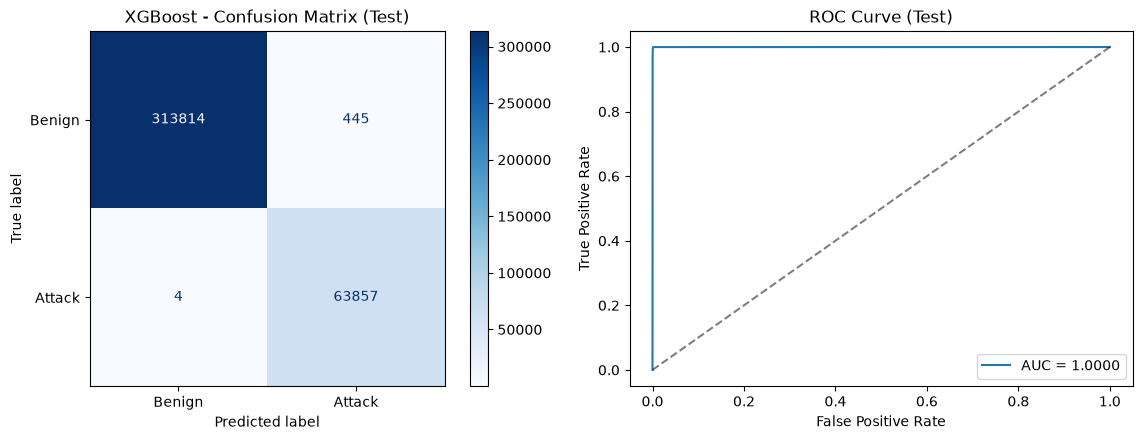

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Attack"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title("XGBoost - Confusion Matrix (Test)")

fpr, tpr, _ = roc_curve(y_test, test_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {test_m['roc_auc']:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve (Test)"); ax[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/xgboost_clean_cm_roc.png", dpi=150)
plt.show()

In [9]:
import joblib
feature_names = joblib.load(f"{DATA_DIR}/feature_names.joblib")
print(len(feature_names), "features loaded")

70 features loaded


## Step 6: Top feature importances

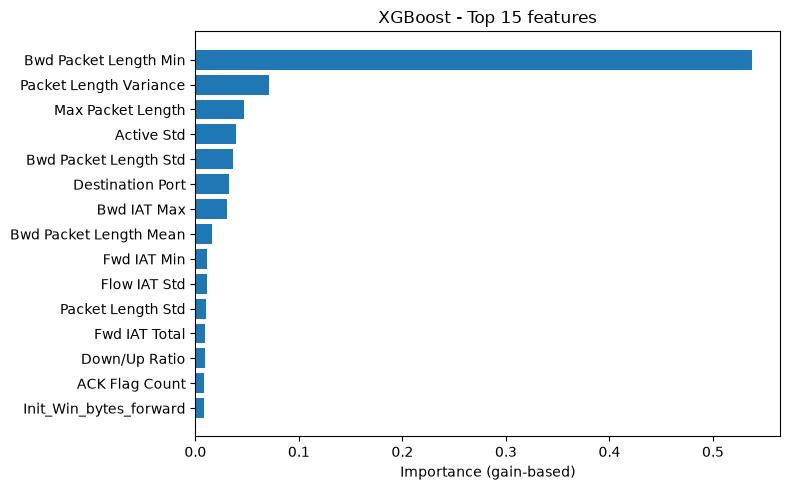

In [10]:
imp = xgb.feature_importances_
top = np.argsort(imp)[::-1][:15]

plt.figure(figsize=(8, 5))
plt.barh([feature_names[i] for i in top][::-1], imp[top][::-1])
plt.xlabel("Importance (gain-based)")
plt.title("XGBoost - Top 15 features")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/xgboost_feature_importance.png", dpi=150)
plt.show()

## Step 7: Save results

In [11]:
with open(f"{RESULT_DIR}/xgboost_clean_metrics.json", "w") as f:
    json.dump({"validation": val_m, "test": test_m, "train_time_s": train_time}, f, indent=2)
print("Saved:", sorted(os.listdir(RESULT_DIR)))

Saved: ['logreg_clean_cm_roc.png', 'logreg_clean_metrics.json', 'svm_clean_cm_roc.png', 'svm_clean_metrics.json', 'xgboost_clean_cm_roc.png', 'xgboost_clean_metrics.json', 'xgboost_feature_importance.png']


## Step 8: Compare with the other models trained so far

In [12]:
models = {"LogReg": "logreg_clean_metrics.json", "LinearSVM": "svm_clean_metrics.json", "XGBoost": "xgboost_clean_metrics.json"}
res = {}
for name, fn_ in models.items():
    p = os.path.join(RESULT_DIR, fn_)
    if os.path.exists(p):
        res[name] = json.load(open(p))["test"]

print(f"{'Metric':14s}" + "".join(f"{n:>12s}" for n in res))
for k in keys:
    print(f"{k:14s}" + "".join(f"{res[n][k]:12.4f}" for n in res))

Metric              LogReg   LinearSVM     XGBoost
accuracy            0.7908      0.7955      0.9988
precision           0.4464      0.4521      0.9931
recall              0.9951      0.9938      0.9999
f1                  0.6163      0.6215      0.9965
specificity         0.7493      0.7553      0.9986
fpr                 0.2507      0.2447      0.0014
fnr                 0.0049      0.0062      0.0001
roc_auc             0.9745      0.9759      1.0000


## Notes for the report and Phase 3
- XGBoost is a tree ensemble, so it is **not differentiable**: FGSM and PGD cannot be applied to it directly. Typical options are (a) a **transfer attack**, crafting adversarial samples on a differentiable surrogate (the DNN or Logistic Regression) and testing them on XGBoost, or (b) black-box attacks such as HopSkipJump or ZOO from the Adversarial Robustness Toolbox.
- Compare **FNR** across models: missed attacks are what adversarial evasion will try to increase.